In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Telecom Customer Churn Project")

data_path = Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
display(df.head())



Telecom Customer Churn Project
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data Cleaning and Preprocessing

In this section, we identify missing values, correct data types,
handle missing TotalCharges values, and check for duplicate records.

In [2]:

# Check dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Convert TotalCharges into numeric values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing TotalCharges
print("\nMissing TotalCharges:")
print(df["TotalCharges"].isnull().sum())

# Fill missing TotalCharges for new customers
df.loc[
    (df["tenure"] == 0) & (df["TotalCharges"].isna()),
    "TotalCharges"
] = 0

# Fill any remaining missing values with median
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

# Check duplicate customer IDs
print("\nDuplicate customer IDs:")
print(df["customerID"].duplicated().sum())

# Verify cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nData cleaning completed!")


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null 

## 3. Outlier Detection Using IQR

The Interquartile Range (IQR) method is used to identify
unusual numerical values in customer tenure and billing data.

Outliers are identified but not automatically removed because
unusual customer spending may contain useful churn information.

In [3]:

# STEP 1: Select numerical columns

numerical_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# STEP 2: Detect outliers using IQR

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print("\nColumn:", column)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))

print("\nOutlier detection completed!")



Column: tenure
Q1: 9.0
Q3: 55.0
IQR: 46.0
Lower Bound: -60.0
Upper Bound: 124.0
Number of Outliers: 0

Column: MonthlyCharges
Q1: 35.5
Q3: 89.85
IQR: 54.349999999999994
Lower Bound: -46.02499999999999
Upper Bound: 171.375
Number of Outliers: 0

Column: TotalCharges
Q1: 398.55
Q3: 3786.6
IQR: 3388.0499999999997
Lower Bound: -4683.525
Upper Bound: 8868.675
Number of Outliers: 0

Outlier detection completed!


## 4. Feature Engineering

Three additional features are created:

1. TenureCohort: Customer tenure groups.
2. AvgMonthlySpendRatio: Ratio of total charges to expected charges.
3. ServiceDensity: Number of selected active customer services.

These features will be used in the predictive models.

In [4]:

# FEATURE 1: TENURE COHORT

df["TenureCohort"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

print("Tenure Cohort Distribution:")
print(df["TenureCohort"].value_counts())

# FEATURE 2: AVERAGE MONTHLY SPEND RATIO

expected_charges = (
    df["MonthlyCharges"] * df["tenure"]
)

df["AvgMonthlySpendRatio"] = (
    df["TotalCharges"] /
    expected_charges.replace(0, np.nan)
)

df["AvgMonthlySpendRatio"] = (
    df["AvgMonthlySpendRatio"]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

# FEATURE 3: SERVICE DENSITY

service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["ServiceDensity"] = (
    df[service_columns] == "Yes"
).sum(axis=1)

# DISPLAY NEW FEATURES

print("\nNew Features:")
display(
    df[
        [
            "tenure",
            "TenureCohort",
            "AvgMonthlySpendRatio",
            "ServiceDensity"
        ]
    ].head()
)

print("\nUpdated Dataset Shape:", df.shape)
print("Feature engineering completed!")


Tenure Cohort Distribution:
TenureCohort
49-72 months    2239
0-12 months     2186
25-48 months    1594
13-24 months    1024
Name: count, dtype: int64

New Features:


,tenure,TenureCohort,AvgMonthlySpendRatio,ServiceDensity
0,1,0-12 months,1.000000,1
1,34,25-48 months,0.975830,3
2,2,0-12 months,1.004178,3
3,45,25-48 months,0.967034,3
4,2,0-12 months,1.072489,1



Updated Dataset Shape: (7043, 24)
Feature engineering completed!


In [5]:

from pathlib import Path

Path("data").mkdir(exist_ok=True)

df.to_csv(
    "data/featured_telco_churn.csv",
    index=False
)

print("Featured dataset saved successfully!")


Featured dataset saved successfully!


## 5. Feature Scaling and Model Comparison

This experiment compares four preprocessing approaches:
1. No Scaling
2. StandardScaler
3. MinMaxScaler
4. RobustScaler

Two classification algorithms are evaluated:
- Logistic Regression
- K-Nearest Neighbors (KNN)

Models are compared using 5-fold stratified cross-validation
on the training dataset. F2-score is prioritized because
identifying customers likely to churn is important for retention.

In [6]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining churn distribution:")
print(y_train.value_counts())


Training samples: 5634
Testing samples: 1409

Training churn distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64


In [7]:

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

from sklearn.metrics import (
    fbeta_score,
    make_scorer
)

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Define scaling methods
scalers = {
    "No Scaling": "passthrough",
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler()
}

# Define classification algorithms
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        solver="liblinear",
        random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

# Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f2": make_scorer(
        fbeta_score,
        beta=2
    )
}

results = []

# Compare each scaler and model
for scaler_name, scaler in scalers.items():

    for model_name, classifier in models.items():

        preprocessor = ColumnTransformer([
            ("num", scaler, numeric_features),
            ("cat", OneHotEncoder(
                handle_unknown="ignore"
            ), categorical_features)
        ])

        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("model", classifier)
        ])

        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=-1
        )

        # Fit separately to record solver iterations
        pipeline.fit(X_train, y_train)

        iterations = None

        if model_name == "Logistic Regression":
            iterations = int(
                pipeline.named_steps["model"].n_iter_[0]
            )

        results.append({
            "Scaler": scaler_name,
            "Model": model_name,
            "Accuracy": scores["test_accuracy"].mean(),
            "Precision": scores["test_precision"].mean(),
            "Recall": scores["test_recall"].mean(),
            "F2_Score": scores["test_f2"].mean(),
            "LR_Iterations": iterations
        })

        print(
            "Completed:",
            scaler_name,
            "-",
            model_name
        )

# Create results table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F2_Score",
    ascending=False
)

print("\nMODEL COMPARISON RESULTS:")
display(results_df)

# Save results
results_df.to_csv(
    "outputs/scaling_comparison_cv.csv",
    index=False
)

print("Scaling comparison completed!")


Completed: No Scaling - Logistic Regression
Completed: No Scaling - KNN
Completed: StandardScaler - Logistic Regression
Completed: StandardScaler - KNN
Completed: MinMaxScaler - Logistic Regression
Completed: MinMaxScaler - KNN
Completed: RobustScaler - Logistic Regression
Completed: RobustScaler - KNN

MODEL COMPARISON RESULTS:


,Scaler,Model,Accuracy,Precision,Recall,F2_Score,LR_Iterations
0,No Scaling,Logistic Regression,0.806533,0.668649,0.537124,0.558859,25.0
2,StandardScaler,Logistic Regression,0.806355,0.668618,0.536455,0.558188,6.0
4,MinMaxScaler,Logistic Regression,0.806533,0.669881,0.535117,0.557162,7.0
6,RobustScaler,Logistic Regression,0.805823,0.668045,0.534448,0.556306,6.0
3,StandardScaler,KNN,0.763400,0.554353,0.555184,0.554907,NaN
5,MinMaxScaler,KNN,0.770501,0.570742,0.545151,0.550059,NaN
7,RobustScaler,KNN,0.755949,0.540661,0.532441,0.534049,NaN
1,No Scaling,KNN,0.765177,0.575153,0.444816,0.465552,NaN


Scaling comparison completed!


In [8]:
from pathlib import Path
Path("outputs").mkdir(exist_ok=True)

In [9]:

best_result = results_df.iloc[0]

print("Best model:", best_result["Model"])
print("Best scaler:", best_result["Scaler"])
print("Best CV F2-score:", best_result["F2_Score"])


Best model: Logistic Regression
Best scaler: No Scaling
Best CV F2-score: 0.5588588330830797


## 6. Decision Threshold Tuning and Final Model Evaluation

The best model is selected using five-fold stratified
cross-validation on the training data.

Out-of-fold training probabilities are used to identify
the decision threshold that maximizes the F2-score.

The final model is then trained on the complete training
dataset and evaluated on the untouched test dataset.

In [10]:

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

# Get best combination from Step 16
best_result = results_df.iloc[0]

best_scaler_name = best_result["Scaler"]
best_model_name = best_result["Model"]

print("Selected scaler:", best_scaler_name)
print("Selected model:", best_model_name)

# Create a fresh preprocessing pipeline
best_preprocessor = ColumnTransformer([
    (
        "num",
        clone(scalers[best_scaler_name])
        if best_scaler_name != "No Scaling"
        else "passthrough",
        numeric_features
    ),
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    )
])

best_pipeline = Pipeline([
    ("preprocessor", best_preprocessor),
    ("model", clone(models[best_model_name]))
])

print("Best pipeline created successfully!")


Selected scaler: No Scaling
Selected model: Logistic Regression
Best pipeline created successfully!


In [11]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    fbeta_score
)

# Obtain out-of-fold probabilities
# Each prediction comes from a model that did
# not train on that particular customer.

oof_probabilities = cross_val_predict(
    best_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Try thresholds from 0.1 to 0.9
thresholds = np.arange(0.1, 1.0, 0.1)

threshold_results = []

for threshold in thresholds:

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(float(threshold), 1),
        "Accuracy": accuracy_score(
            y_train, predictions
        ),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F2_Score": fbeta_score(
            y_train, predictions,
            beta=2,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print("THRESHOLD COMPARISON:")
display(threshold_df)

# Select threshold with highest F2-score
best_index = threshold_df["F2_Score"].idxmax()
best_threshold = float(
    threshold_df.loc[best_index, "Threshold"]
)

print("Best threshold:", best_threshold)

threshold_df.to_csv(
    "outputs/final_threshold_tuning.csv",
    index=False
)


THRESHOLD COMPARISON:


,Threshold,Accuracy,Precision,Recall,F2_Score
0,0.1,0.613241,0.402118,0.939799,0.741503
1,0.2,0.709975,0.474269,0.856856,0.737818
2,0.3,0.768016,0.545062,0.760535,0.704810
3,0.4,0.791090,0.597906,0.649498,0.638480
4,0.5,0.806532,0.668609,0.537124,0.559114
5,0.6,0.796770,0.714988,0.389298,0.428319
6,0.7,0.781505,0.788210,0.241472,0.280367
7,0.8,0.751154,0.918919,0.068227,0.083730
8,0.9,0.734647,0.000000,0.000000,0.000000


Best threshold: 0.1


In [12]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# Train selected model on all training data
best_pipeline.fit(X_train, y_train)

# Predict probabilities for untouched test data
test_probabilities = best_pipeline.predict_proba(
    X_test
)[:, 1]

# Apply threshold selected using training data
final_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Calculate final test metrics
final_accuracy = accuracy_score(
    y_test, final_predictions
)

final_precision = precision_score(
    y_test, final_predictions,
    zero_division=0
)

final_recall = recall_score(
    y_test, final_predictions,
    zero_division=0
)

final_f2 = fbeta_score(
    y_test, final_predictions,
    beta=2,
    zero_division=0
)

print("FINAL TEST RESULTS")
print("Selected model:", best_model_name)
print("Selected scaler:", best_scaler_name)
print("Selected threshold:", best_threshold)

print("Accuracy:", final_accuracy)
print("Precision:", final_precision)
print("Recall:", final_recall)
print("F2 Score:", final_f2)

# Classification report
report = classification_report(
    y_test,
    final_predictions,
    target_names=["No Churn", "Churn"],
    zero_division=0
)

print("\nCLASSIFICATION REPORT:")
print(report)

with open(
    "outputs/final_classification_report.txt",
    "w"
) as file:
    file.write(report)

# Save final metrics
final_metrics = pd.DataFrame([{
    "Model": best_model_name,
    "Scaler": best_scaler_name,
    "Threshold": best_threshold,
    "Accuracy": final_accuracy,
    "Precision": final_precision,
    "Recall": final_recall,
    "F2_Score": final_f2
}])

final_metrics.to_csv(
    "outputs/final_test_metrics.csv",
    index=False
)

print("Final evaluation completed!")


FINAL TEST RESULTS
Selected model: Logistic Regression
Selected scaler: No Scaling
Selected threshold: 0.1
Accuracy: 0.6075230660042583
Precision: 0.399098083427283
Recall: 0.946524064171123
F2 Score: 0.7427612253462023

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    No Churn       0.96      0.49      0.64      1035
       Churn       0.40      0.95      0.56       374

    accuracy                           0.61      1409
   macro avg       0.68      0.72      0.60      1409
weighted avg       0.81      0.61      0.62      1409

Final evaluation completed!


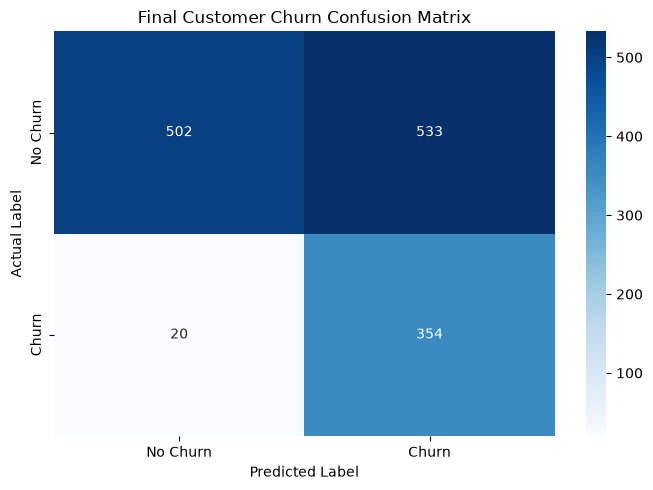

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    final_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Final Customer Churn Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "outputs/final_confusion_matrix.png",
    dpi=300
)

plt.show()


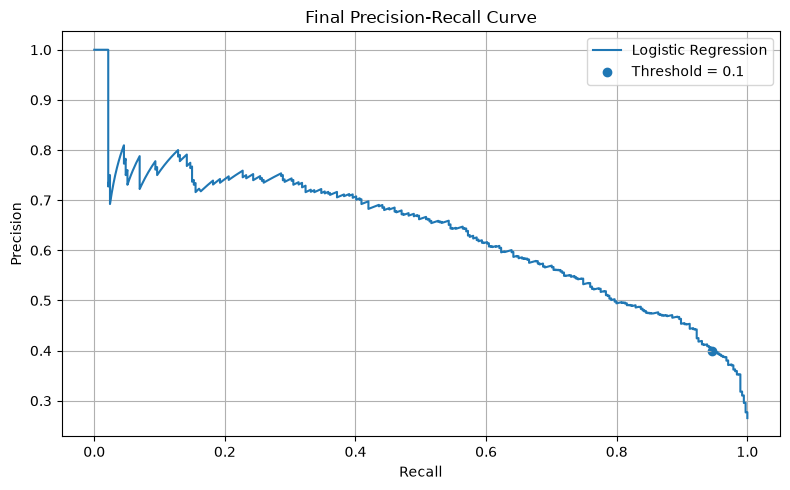

In [14]:

from sklearn.metrics import precision_recall_curve

precision, recall, pr_thresholds = (
    precision_recall_curve(
        y_test,
        test_probabilities
    )
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision,
    label=best_model_name
)

# Mark the selected threshold
selected_precision = precision_score(
    y_test, final_predictions,
    zero_division=0
)

selected_recall = recall_score(
    y_test, final_predictions,
    zero_division=0
)

plt.scatter(
    selected_recall,
    selected_precision,
    label=f"Threshold = {best_threshold:.1f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Final Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "outputs/final_precision_recall_curve.png",
    dpi=300
)

plt.show()


## 7. Customer Retention Cost–Benefit Analysis

This section estimates the financial impact of using churn
predictions to target customer retention campaigns.

We calculate:
- Number of customers targeted
- Number of actual churners identified
- Estimated campaign costs
- Expected retention benefits
- Net benefit and return on investment (ROI)

All financial parameters are illustrative assumptions
and do not represent actual telecom company financial data.

In [15]:

# BUSINESS ASSUMPTIONS

contact_cost = 100
customer_retention_value = 5000
campaign_success_rate = 0.30

print("Cost per customer: ₹", contact_cost)
print("Retention value: ₹", customer_retention_value)
print("Campaign success rate:", campaign_success_rate)


Cost per customer: ₹ 100
Retention value: ₹ 5000
Campaign success rate: 0.3


In [16]:

# CUSTOMERS PREDICTED TO CHURN
targeted_customers = int(
    (final_predictions == 1).sum()
)

# ACTUAL CHURNERS CORRECTLY IDENTIFIED
true_positives = int(
    (
        (final_predictions == 1) &
        (np.asarray(y_test) == 1)
    ).sum()
)

# NON-CHURNERS INCORRECTLY TARGETED
false_positives = int(
    (
        (final_predictions == 1) &
        (np.asarray(y_test) == 0)
    ).sum()
)

# CAMPAIGN COST
total_campaign_cost = (
    targeted_customers * contact_cost
)

# EXPECTED CUSTOMERS SUCCESSFULLY RETAINED
expected_retained_customers = (
    true_positives * campaign_success_rate
)

# EXPECTED FINANCIAL BENEFIT
expected_benefit = (
    expected_retained_customers *
    customer_retention_value
)

# NET BENEFIT
net_benefit = (
    expected_benefit - total_campaign_cost
)

# RETURN ON INVESTMENT
roi = (
    (net_benefit / total_campaign_cost) * 100
    if total_campaign_cost > 0
    else 0
)

print("RETENTION CAMPAIGN ANALYSIS")
print("Targeted customers:", targeted_customers)
print("True positives:", true_positives)
print("False positives:", false_positives)
print("Expected retained customers:", expected_retained_customers)
print("Campaign cost: ₹", total_campaign_cost)
print("Expected benefit: ₹", expected_benefit)
print("Net benefit: ₹", net_benefit)
print("ROI:", round(roi, 2), "%")


RETENTION CAMPAIGN ANALYSIS
Targeted customers: 887
True positives: 354
False positives: 533
Expected retained customers: 106.2
Campaign cost: ₹ 88700
Expected benefit: ₹ 531000.0
Net benefit: ₹ 442300.0
ROI: 498.65 %


,Threshold,Targeted,True_Positives,False_Positives,Campaign_Cost,Expected_Benefit,Net_Benefit,ROI_Percent
0,0.1,887,354,533,88700,531000.0,442300.0,498.647125
1,0.2,681,323,358,68100,484500.0,416400.0,611.453744
2,0.3,535,284,251,53500,426000.0,372500.0,696.261682
3,0.4,417,244,173,41700,366000.0,324300.0,777.697842
4,0.5,287,190,97,28700,285000.0,256300.0,893.031359
5,0.6,196,139,57,19600,208500.0,188900.0,963.775510
6,0.7,111,84,27,11100,126000.0,114900.0,1035.135135
7,0.8,25,19,6,2500,28500.0,26000.0,1040.000000
8,0.9,0,0,0,0,0.0,0.0,0.000000


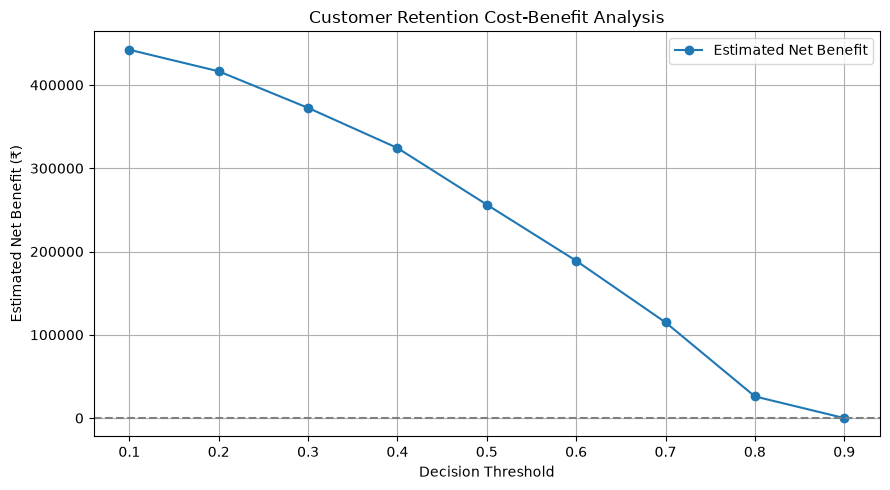

Cost-benefit analysis completed!


In [17]:

# COMPARE DIFFERENT THRESHOLDS

threshold_values = np.arange(0.1, 1.0, 0.1)

business_results = []

for threshold in threshold_values:

    predictions = (
        test_probabilities >= threshold
    ).astype(int)

    targeted = int(predictions.sum())

    tp = int(
        (
            (predictions == 1) &
            (np.asarray(y_test) == 1)
        ).sum()
    )

    fp = targeted - tp

    cost = targeted * contact_cost

    benefit = (
        tp *
        campaign_success_rate *
        customer_retention_value
    )

    net = benefit - cost

    threshold_roi = (
        net / cost * 100
        if cost > 0
        else 0
    )

    business_results.append({
        "Threshold": round(float(threshold), 1),
        "Targeted": targeted,
        "True_Positives": tp,
        "False_Positives": fp,
        "Campaign_Cost": cost,
        "Expected_Benefit": benefit,
        "Net_Benefit": net,
        "ROI_Percent": threshold_roi
    })

business_df = pd.DataFrame(business_results)

display(business_df)

business_df.to_csv(
    "outputs/retention_cost_benefit.csv",
    index=False
)

# PLOT COST-BENEFIT CURVE

plt.figure(figsize=(9, 5))

plt.plot(
    business_df["Threshold"],
    business_df["Net_Benefit"],
    marker="o",
    label="Estimated Net Benefit"
)

plt.axhline(
    y=0,
    color="gray",
    linestyle="--"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Estimated Net Benefit (₹)")
plt.title("Customer Retention Cost-Benefit Analysis")

plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    "outputs/retention_cost_benefit.png",
    dpi=300
)

plt.show()

print("Cost-benefit analysis completed!")


In [18]:

# DESCRIPTIVE ANALYSIS ONLY
# Do not use this to reselect the final model threshold.

highest_benefit_row = business_df.loc[
    business_df["Net_Benefit"].idxmax()
]

print("Highest observed estimated net benefit:")
print("Threshold:", highest_benefit_row["Threshold"])
print("Net benefit: ₹", highest_benefit_row["Net_Benefit"])

print("\nFinal model threshold remains:", best_threshold)


Highest observed estimated net benefit:
Threshold: 0.1
Net benefit: ₹ 442300.0

Final model threshold remains: 0.1


## 8. Results and Discussion

This project evaluates customer churn prediction using
Logistic Regression and K-Nearest Neighbors (KNN).

Four preprocessing methods were compared:
- No Scaling
- StandardScaler
- MinMaxScaler
- RobustScaler

Five-fold stratified cross-validation was used for model
comparison, and the F2-score was prioritized to identify
customers at risk of leaving.

The selected model was evaluated on a separate test set.
A retention cost-benefit analysis was also conducted using
illustrative business assumptions.

In [19]:

# FINAL PROJECT RESULTS

summary = pd.DataFrame([{
    "Best Model": best_model_name,
    "Best Scaler": best_scaler_name,
    "Selected Threshold": best_threshold,
    "Test Accuracy": final_accuracy,
    "Test Precision": final_precision,
    "Test Recall": final_recall,
    "Test F2 Score": final_f2,
    "Campaign Cost": total_campaign_cost,
    "Expected Benefit": expected_benefit,
    "Net Benefit": net_benefit,
    "ROI (%)": roi
}])

print("FINAL PROJECT SUMMARY")
display(summary.T)

summary.to_csv(
    "outputs/final_project_summary.csv",
    index=False
)

print("Final summary saved successfully!")


FINAL PROJECT SUMMARY


,0
Best Model,Logistic Regression
Best Scaler,No Scaling
Selected Threshold,0.1
Test Accuracy,0.607523
Test Precision,0.399098
Test Recall,0.946524
Test F2 Score,0.742761
Campaign Cost,88700
Expected Benefit,531000.0
Net Benefit,442300.0


Final summary saved successfully!


In [20]:

conclusion = f"""
PROJECT CONCLUSION

This project developed a customer churn prediction
pipeline using the Telco Customer Churn dataset.

The selected classification algorithm was
{best_model_name}, using {best_scaler_name}.

The decision threshold was {best_threshold:.2f}.

On the held-out test dataset, the model achieved:
Accuracy: {final_accuracy:.4f}
Precision: {final_precision:.4f}
Recall: {final_recall:.4f}
F2-score: {final_f2:.4f}

Using the illustrative retention campaign assumptions,
the estimated net benefit was Rs. {net_benefit:,.2f},
with an estimated ROI of {roi:.2f}%.

These financial estimates depend on assumed costs,
customer value, and campaign effectiveness.

The results demonstrate how classification models
can support customer retention decisions.
"""

print(conclusion)

with open(
    "outputs/project_conclusion.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(conclusion)



PROJECT CONCLUSION

This project developed a customer churn prediction
pipeline using the Telco Customer Churn dataset.

The selected classification algorithm was
Logistic Regression, using No Scaling.

The decision threshold was 0.10.

On the held-out test dataset, the model achieved:
Accuracy: 0.6075
Precision: 0.3991
Recall: 0.9465
F2-score: 0.7428

Using the illustrative retention campaign assumptions,
the estimated net benefit was Rs. 442,300.00,
with an estimated ROI of 498.65%.

These financial estimates depend on assumed costs,
customer value, and campaign effectiveness.

The results demonstrate how classification models
can support customer retention decisions.



## 9. Limitations and Future Scope

### Limitations

1. The dataset represents a historical sample of telecom customers.
2. Model performance may change when applied to new customers.
3. The dataset contains class imbalance between churn and non-churn customers.
4. The retention campaign costs and benefits are illustrative assumptions.
5. The model predicts churn risk but does not establish why a customer leaves.

### Future Scope

1. Compare additional classification algorithms.
2. Investigate advanced hyperparameter tuning.
3. Apply explainable AI methods to understand predictions.
4. Evaluate the model on more recent customer data.
5. Test retention strategies using controlled experiments.

In [22]:
print("Final Confusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

print("\nCampaign assumptions:")
print("Contact cost:", contact_cost)
print("Retention value:", customer_retention_value)
print("Success rate:", campaign_success_rate)

Final Confusion Matrix:
[[502 533]
 [ 20 354]]

Campaign assumptions:
Contact cost: 100
Retention value: 5000
Success rate: 0.3
